In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Load Sniff Locking and Spatial Information CSVs

In [2]:
sniff_path = 'E:/cbm-odor/sniff/sniff_locking.csv'
space_path = 'E:/cbm-odor/sniff/spatial_info_search.csv'
space_data = pd.read_csv(space_path)
sniff_lock_data = pd.read_csv(sniff_path)
display(space_data.tail(5))
display(sniff_lock_data.tail(5))

,mouse,session,region,cluster,group,n_spikes,epoch_duration_s,n_bins_visited,n_spikes_tracked,si_bits_per_spike,ssi,p_empirical,p_gaussian,null_mean_bits_per_spike,null_sd_bits_per_spike
4910,9009,x9,ob,9,mua,22062,1864.882899,105,16253.0,0.008068,1.501380,0.076,6.662872e-02,0.006678,0.000925
4911,9009,x9,ob,10,mua,18876,1864.882899,105,13668.0,0.014790,5.765316,0.000,4.075249e-09,0.007945,0.001187
4912,9009,x9,ob,16,mua,56667,1864.882899,105,41431.0,0.004116,3.292223,0.003,4.969946e-04,0.002820,0.000394
4913,9009,x9,ob,18,mua,44116,1864.882899,105,31650.0,0.004313,-0.222499,0.557,5.880372e-01,0.004483,0.000765
4914,9009,x9,ob,19,mua,38760,1864.882899,105,28262.0,0.004648,-0.066060,0.511,5.263349e-01,0.004694,0.000700


,mouse,session,region,cluster,group,n_spikes,n_spikes_in_window,n_sniffs,rate_in_window_hz,info_bits_per_spike,info_bits_per_s,info_corrected_bits_per_spike,info_corrected_bits_per_s,info_z,info_p,shuffle_mean_bits_per_spike,shuffle_sd_bits_per_spike,peak_latency_ms,peak_rate_hz
4910,9009,x9,ob,9,mua,22062,15612,14111,8.681909,0.257920,2.239242,0.251087,2.179918,247.195674,0.001996,0.006833,0.001016,70.0,16.908991
4911,9009,x9,ob,10,mua,18876,13101,14111,7.285530,0.221239,1.611841,0.215783,1.572097,247.604687,0.001996,0.005455,0.000871,74.0,13.614829
4912,9009,x9,ob,16,mua,56667,39288,14111,21.848248,0.030580,0.668122,0.028837,0.630042,95.727720,0.001996,0.001743,0.000301,82.0,27.664425
4913,9009,x9,ob,18,mua,44116,29813,14111,16.579154,0.023833,0.395136,0.022353,0.370592,79.017725,0.001996,0.001480,0.000283,76.0,21.650371
4914,9009,x9,ob,19,mua,38760,26674,14111,14.833541,0.028872,0.428281,0.027252,0.404247,88.935372,0.001996,0.001620,0.000306,74.0,19.735321


# Create Spatio-Temporal Information Index

In [3]:
keys = ['mouse', 'session', 'region', 'cluster']
st_info_df = sniff_lock_data[keys + ['group', 'n_spikes', 'peak_latency_ms', 'info_bits_per_spike', 'info_z', 'info_p']].merge(
    space_data[keys + ['si_bits_per_spike', 'ssi', 'p_empirical']],
    on=keys, how='inner', validate='one_to_one',
)

# Use shuffle-normalized z-scores (removes low-spike-count bias), then percentile-rank within region
# so the two measures share a scale and OB/HC differences don't dominate.
st_info_df['t_pct'] = st_info_df.groupby('region')['info_z'].rank(pct=True)
st_info_df['s_pct'] = st_info_df.groupby('region')['ssi'].rank(pct=True)

# min() is high only when BOTH are high, so neither dimension can carry the score alone
st_info_df['st_info_index'] = st_info_df[['t_pct', 's_pct']].min(axis=1)
st_info_df['st_imbalance'] = (st_info_df['t_pct'] - st_info_df['s_pct']).abs()
st_info_df['sig_both'] = (st_info_df['info_p'] < 0.05) & (st_info_df['p_empirical'] < 0.05)
display(st_info_df.head(5))

,mouse,session,region,cluster,group,n_spikes,peak_latency_ms,info_bits_per_spike,info_z,info_p,si_bits_per_spike,ssi,p_empirical,t_pct,s_pct,st_info_index,st_imbalance,sig_both
0,9000,o2,hc,0,mua,15869,182.0,0.002629,-0.913839,0.826347,0.015355,7.251900,0.000,0.077706,0.337300,0.077706,0.259594,False
1,9000,o2,hc,1,NaN,98878,0.0,0.000835,3.348937,0.005988,0.012469,18.399444,0.001,0.724805,0.718463,0.718463,0.006342,True
2,9000,o2,hc,2,NaN,5021,0.0,0.011834,-0.720472,0.762475,0.123026,0.637220,0.196,0.103495,0.026862,0.026862,0.076633,False
3,9000,o2,hc,3,NaN,30647,248.0,0.001971,1.354104,0.111776,0.013608,6.091249,0.000,0.485579,0.282557,0.282557,0.203022,False
4,9000,o2,hc,4,NaN,73950,0.0,0.000580,-0.215162,0.560878,0.054649,33.298044,0.000,0.181880,0.924855,0.181880,0.742976,False


In [4]:
st_info_sorted = st_info_df[st_info_df['sig_both']].sort_values(by='st_info_index', ascending=False)
display(st_info_sorted.head(25))

,mouse,session,region,cluster,group,n_spikes,peak_latency_ms,info_bits_per_spike,info_z,info_p,si_bits_per_spike,ssi,p_empirical,t_pct,s_pct,st_info_index,st_imbalance,sig_both
358,9000,x2,hc,18,mua,97722,38.0,0.031757,67.740606,0.001996,0.168856,63.988385,0.000,0.996946,0.990139,0.990139,0.006807,True
3803,9008,t2,ob,7,mua,42066,72.0,0.651220,607.408606,0.001996,0.046408,48.614318,0.000,0.984756,0.998476,0.984756,0.013720,True
3801,9008,t2,ob,5,mua,35315,72.0,0.694361,583.216652,0.001996,0.038049,27.558319,0.000,0.983740,0.985772,0.983740,0.002033,True
3575,9007,x4,hc,16,mua,106022,30.0,0.009859,31.102376,0.001996,0.136554,55.026153,0.000,0.982694,0.981979,0.981979,0.000715,True
3574,9007,x4,hc,15,mua,98847,44.0,0.008735,28.601861,0.001996,0.126081,53.514504,0.000,0.977604,0.980959,0.977604,0.003355,True
357,9000,x2,hc,17,mua,93526,36.0,0.031045,74.049985,0.001996,0.170663,48.630309,0.000,0.998303,0.974838,0.974838,0.023465,True
3517,9007,x2,hc,18,mua,91426,32.0,0.008394,26.439645,0.001996,0.099147,49.183199,0.000,0.972854,0.976199,0.972854,0.003345,True
2565,9006,t3,hc,0,mua,86654,2.0,0.004928,20.036377,0.001996,0.032069,48.230569,0.000,0.960977,0.973818,0.960977,0.012841,True
4642,9009,x2,ob,2,good,82570,84.0,0.388709,443.121011,0.001996,0.013971,24.482498,0.000,0.958333,0.978659,0.958333,0.020325,True
1395,9003,x1,hc,16,mua,21890,34.0,0.053154,19.166332,0.001996,0.414062,49.430063,0.000,0.958263,0.976879,0.958263,0.018616,True


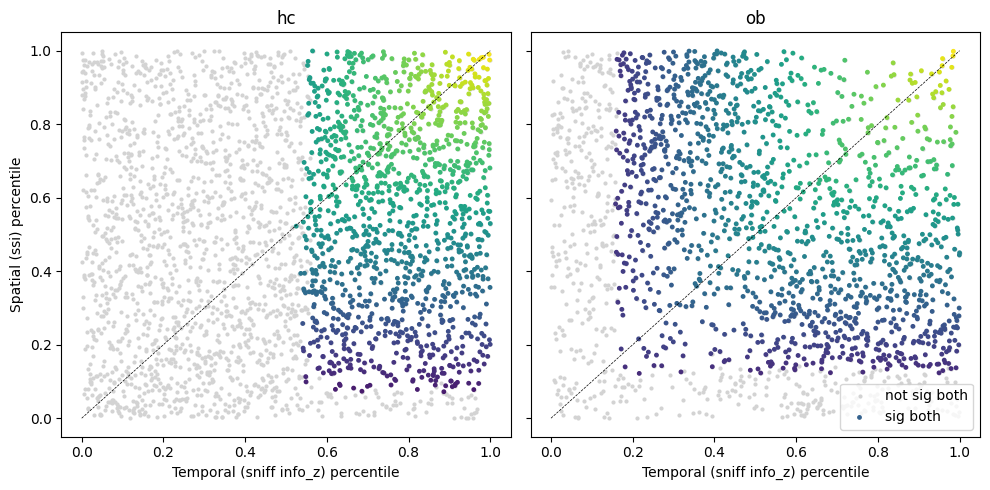

In [5]:
fig, axes = plt.subplots(1, st_info_df['region'].nunique(), figsize=(10, 5), sharex=True, sharey=True)
for ax, (region, df) in zip(np.atleast_1d(axes), st_info_df.groupby('region')):
    ax.scatter(df['t_pct'], df['s_pct'], s=4, c='lightgray', label='not sig both')
    sig = df[df['sig_both']]
    ax.scatter(sig['t_pct'], sig['s_pct'], s=6, c=sig['st_info_index'], cmap='viridis', vmin=0, vmax=1, label='sig both')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.5)
    ax.set_title(region)
    ax.set_xlabel('Temporal (sniff info_z) percentile')
ax.legend(loc='lower right')
np.atleast_1d(axes)[0].set_ylabel('Spatial (ssi) percentile')
plt.tight_layout()
plt.show()

### Sniff and Spatial Units Separately

In [6]:
sl_sorted = sniff_lock_data.sort_values(by='info_bits_per_spike', ascending=False)
# Only take rows with 'x' in the session column
sl_sorted = sl_sorted[sl_sorted['session'].str.contains('x')]
display(sl_sorted.head(5))

,mouse,session,region,cluster,group,n_spikes,n_spikes_in_window,n_sniffs,rate_in_window_hz,info_bits_per_spike,info_bits_per_s,info_corrected_bits_per_spike,info_corrected_bits_per_s,info_z,info_p,shuffle_mean_bits_per_spike,shuffle_sd_bits_per_spike,peak_latency_ms,peak_rate_hz
1589,9003,x8,ob,11,good,68302,49903,14377,24.877018,0.581225,14.459141,0.577042,14.355081,833.703301,0.001996,0.004183,0.000692,68.0,74.324931
4752,9009,x4,ob,2,mua,42845,28425,11299,18.068602,0.467521,8.447443,0.459979,8.311184,485.789980,0.001996,0.007541,0.000947,86.0,44.126302
780,9002,x1,hc,5,good,124,81,13183,0.044861,0.465953,0.020903,0.013997,0.000628,0.185624,0.427146,0.451956,0.075404,162.0,0.261392
4758,9009,x4,ob,8,mua,22933,15591,11299,9.910556,0.457654,4.535602,0.447855,4.438492,355.013198,0.001996,0.009799,0.001262,72.0,22.063578
4756,9009,x4,ob,6,mua,25677,17803,11299,11.316634,0.449928,5.091674,0.436742,4.942454,315.506919,0.001996,0.013186,0.001384,72.0,23.994088


In [7]:
hc_sorted = sl_sorted[sl_sorted['region'].str.contains('hc')].sort_values(by='info_z', ascending=False)
hc_sorted.head(5)

,mouse,session,region,cluster,group,n_spikes,n_spikes_in_window,n_sniffs,rate_in_window_hz,info_bits_per_spike,info_bits_per_s,info_corrected_bits_per_spike,info_corrected_bits_per_s,info_z,info_p,shuffle_mean_bits_per_spike,shuffle_sd_bits_per_spike,peak_latency_ms,peak_rate_hz
2233,9005,x6,hc,6,good,155534,117672,15017,61.743728,0.015834,0.977656,0.015396,0.950588,211.367838,0.001996,0.000438,0.000073,2.0,79.584874
2996,9006,x4,hc,21,good,12725,9018,13703,4.716039,0.091848,0.433158,0.087259,0.411515,92.505711,0.001996,0.004589,0.000943,100.0,8.813790
357,9000,x2,hc,17,mua,93526,54392,14704,27.086557,0.031045,0.840907,0.029055,0.786992,74.049985,0.001996,0.001990,0.000392,36.0,54.623913
3063,9006,x5,hc,9,good,10601,7854,13460,4.243506,0.074661,0.316825,0.069773,0.296084,71.845045,0.001996,0.004888,0.000971,106.0,6.945459
1895,9005,x1,hc,17,mua,87294,59394,16685,29.091034,0.014450,0.420362,0.013585,0.395200,71.613529,0.001996,0.000865,0.000190,28.0,46.765180
